# Ensemble Methods Case Study

Jose Mariano C. Leechiu

In [ ]:

# Load libraries
import pandas as pd
from sklearn.tree import DecisionTreeClassifier # Import Decision Tree Classifier
from sklearn.model_selection import train_test_split # Import train_test_split function
from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation


import os
import re
import numpy as np
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, classification_report, precision_score, recall_score,
    f1_score, roc_auc_score
)
from pathlib import Path
import matplotlib.pyplot as plt



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Use the Online News Popularity from a few case studies ago


In [ ]:
# MASHABLE DATA:
mashable_test_Directory = Path("MashableData/OnlineNewsPopularityTest.csv")
mashable_training_Directory = Path("MashableData/OnlineNewsPopularityTraining.csv")

In [ ]:
#Part 2A
import pandas as pd

# Load data
train_path = "MashableData/OnlineNewsPopularityTraining.csv"
test_path = "MashableData/OnlineNewsPopularityTest.csv"

X_train_full = pd.read_csv(train_path)
X_test_full = pd.read_csv(test_path)

# Create binary target
y_train = (X_train_full['shares'] > X_train_full['shares'].median()).astype(int)
y_test = (X_test_full['shares'] > X_test_full['shares'].median()).astype(int)

# Use ONLY top 15 features (fastest)
numeric_cols = X_train_full.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols.remove('shares')
top_features = X_train_full[numeric_cols].var().nlargest(15).index.tolist()

X_train = X_train_full[top_features].fillna(X_train_full[top_features].mean())
X_test = X_test_full[top_features].fillna(X_test_full[top_features].mean())
results = []

# ─── DECISION TREE ───
dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [5, 10], 'min_samples_split': [5, 10]},
    cv=2, scoring='accuracy', n_jobs=-1
)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
dt_proba = dt.predict_proba(X_test)[:, 1]
results.append({
    'Model': 'Decision Tree',
    'Accuracy': accuracy_score(y_test, dt_pred),
    'Precision': precision_score(y_test, dt_pred),
    'Recall': recall_score(y_test, dt_pred),
    'F1': f1_score(y_test, dt_pred),
    'ROC-AUC': roc_auc_score(y_test, dt_proba),
    'MSPE': np.mean((dt_proba - y_test)**2)
})

# ─── BAGGING ───
bag = GridSearchCV(
    BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=8), random_state=42),
    {'n_estimators': [50, 100], 'max_samples': [0.8, 1.0]},
    cv=2, scoring='accuracy', n_jobs=-1
)
bag.fit(X_train, y_train)
bag_pred = bag.predict(X_test)
bag_proba = bag.predict_proba(X_test)[:, 1]
results.append({
    'Model': 'Bagging',
    'Accuracy': accuracy_score(y_test, bag_pred),
    'Precision': precision_score(y_test, bag_pred),
    'Recall': recall_score(y_test, bag_pred),
    'F1': f1_score(y_test, bag_pred),
    'ROC-AUC': roc_auc_score(y_test, bag_proba),
    'MSPE': np.mean((bag_proba - y_test)**2)
})

# ─── RANDOM FOREST ───
rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    {'n_estimators': [100], 'max_depth': [10, 15], 'max_features': ['sqrt']},
    cv=2, scoring='accuracy', n_jobs=-1
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]
results.append({
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_test, rf_pred),
    'Precision': precision_score(y_test, rf_pred),
    'Recall': recall_score(y_test, rf_pred),
    'F1': f1_score(y_test, rf_pred),
    'ROC-AUC': roc_auc_score(y_test, rf_proba),
    'MSPE': np.mean((rf_proba - y_test)**2)
})

# RESULTS
df_results = pd.DataFrame(results)
print("\n" + "="*100)
print("PART 2(a) RESULTS")
print("="*100)
print(df_results.to_string(index=False))
print("="*100 + "\n")


# Best model
best = df_results.loc[df_results['Accuracy'].idxmax()]
print(f" BEST MODEL: {best['Model']} (Accuracy: {best['Accuracy']:.4f})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

PART 2(a) RESULTS
        Model  Accuracy  Precision   Recall       F1  ROC-AUC     MSPE
Decision Tree  0.622099   0.593524 0.737382 0.657678 0.668817 0.228289
      Bagging  0.645055   0.632128 0.667435 0.649302 0.697514 0.220950
Random Forest  0.642407   0.632375 0.653600 0.642812 0.699256 0.220033

 BEST MODEL: Bagging (Accuracy: 0.6451)


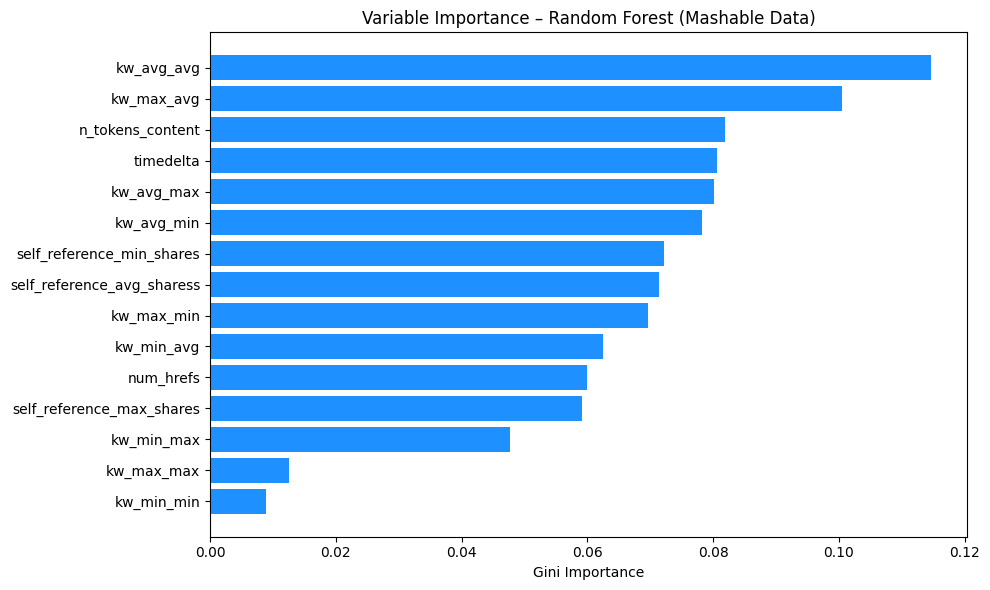

In [ ]:
# PART 2B

# Extract the best model from the GridSearch performed in Part 2A
best_rf_mashable = rf.best_estimator_

# Get feature importances
importances = best_rf_mashable.feature_importances_
feature_names = top_features  # The 15 features selected in Part 2A

# Sort them for the plot
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title("Variable Importance – Random Forest (Mashable Data)")
plt.barh(range(len(indices)), importances[indices], color='dodgerblue', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Gini Importance")
plt.tight_layout()
plt.show()

PART 2C:

Our MSPE results are as follows:
Decision Tree = 0.2283
Bagging = 0.2210
Random Forest = 0.2200

From this, we can conclude that Random Forest achieved the lowest MSPE. Even though Bagging had better accuracy, the Random Forest's lower MSPE shows that its predicted probabilities were closer to the actual outcomes on average.

In comparison to last homework's models, we used PCA to handle the high dimensionality of the data. By using Random Forest, it calculates the variable importance and basically ignores features that aren't necessary.

The advantages of using ensemble methods are better probability estimates and variance reduction. Bagging and Random Forest reduce the instability of a single tree. Then, we average many trees and the model is less likely to overfit outliers. The disadvantages are the computational cost and reduced interpretability. It's much harder to understand and explain the logic of all the combined trees, and overall the process is CPU-intensive and slower than a simpler model like KNN.

Running on Naive Bayes Spam Email:

In [ ]:
from pathlib import Path

#Naive Files:
spam_training_directory = Path("/content/drive/MyDrive/NaiveBayes/TRAINING")
spam_labels_file = Path("/content/drive/MyDrive/NaiveBayes/SPAMTrain.label")
spam_testing_directory = Path("/content/drive/MyDrive/NaiveBayes/TESTING")


training_names = sorted(os.listdir(spam_training_directory))
training_names = [f for f in training_names if f.endswith(".eml")]
print("Number of training files:", len(training_names))


training_emails = []
for fname in training_names:
    with open(spam_training_directory / fname, "r", encoding="latin-1", errors="ignore") as f:
        training_emails.append(f.readlines())


# Labels:
labels = pd.read_table(spam_labels_file, header=None)
y = labels.iloc[:, 0].apply(lambda x: int(str(x).split()[0])).values
print("Number of labels:", len(y))


# feature matrix:
email_texts = [" ".join(email).lower() for email in training_emails]

keywords = [
    "free", "money", "credit", "remove", "order", "business", "internet",
    "email", "click", "million", "dollar", "price", "guarantee", "sex",
    "offer", "winner", "urgent", "limited", "discount",
    "buy", "bonus", "cash", "trial", "explosive", "deposit",
    "act now", "no obligation", "opportunity"
]

feature_data = {}
for word in keywords:
    feature_data[word] = [1 if word in text else 0 for text in email_texts]

feature_data["has_exclamation"] = [1 if "!" in text else 0 for text in email_texts]
feature_data["has_dollar_sign"] = [1 if "$" in text else 0 for text in email_texts]
feature_data["has_html"]        = [1 if "<html" in text or "href" in text else 0 for text in email_texts]
feature_data["has_number"]      = [1 if re.search(r"\d", text) else 0 for text in email_texts]
feature_data["has_caps_word"]   = [
    1 if re.search(r"\b[A-Z]{2,}\b", " ".join(training_emails[i])) else 0
    for i in range(len(training_emails))
]

X = pd.DataFrame(feature_data)
print("\nFeature matrix shape:", X.shape)

Number of training files: 4327
Number of labels: 4327

Feature matrix shape: (4327, 33)


In [ ]:

# ── Naive Bayes
nb_model = BernoulliNB()
nb_model.fit(X, y)
nb_preds = nb_model.predict(X)
nb_acc   = accuracy_score(y, nb_preds)
nb_mspe  = np.mean((y - nb_preds) ** 2)

print("\n=== Naive Bayes ===")
print("Accuracy:", round(nb_acc, 4))
print("MSPE:    ", round(nb_mspe, 4))




=== Naive Bayes ===
Accuracy: 0.9018
MSPE:     0.0982


In [ ]:

# 1. Classification Tree
tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={
        "max_depth"        : [3, 5, 10, None],
        "min_samples_split": [2, 10, 20],
        "criterion"        : ["gini", "entropy"],
    },
    cv=5, scoring="accuracy"
)
tree_grid.fit(X, y)
best_tree  = tree_grid.best_estimator_
tree_preds = best_tree.predict(X)
tree_acc   = accuracy_score(y, tree_preds)
tree_mspe  = np.mean((y - tree_preds) ** 2)

print("\n=== Classification Tree ===")
print("Best params:", tree_grid.best_params_)
print("Accuracy:   ", round(tree_acc, 4))
print("MSPE:       ", round(tree_mspe, 4))
print(classification_report(y, tree_preds, target_names=["Ham", "Spam"]))



=== Classification Tree ===
Best params: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 2}
Accuracy:    0.9478
MSPE:        0.0522
              precision    recall  f1-score   support

         Ham       0.95      0.89      0.92      1378
        Spam       0.95      0.98      0.96      2949

    accuracy                           0.95      4327
   macro avg       0.95      0.93      0.94      4327
weighted avg       0.95      0.95      0.95      4327



In [ ]:

# 2. Bagging
bag_grid = GridSearchCV(
    BaggingClassifier(random_state=42),
    param_grid={
        "n_estimators": [50, 100, 200],
        "max_samples" : [0.7, 0.9, 1.0]
    },
    cv=5, scoring="accuracy"
)
bag_grid.fit(X, y)
best_bag  = bag_grid.best_estimator_
bag_preds = best_bag.predict(X)
bag_acc   = accuracy_score(y, bag_preds)
bag_mspe  = np.mean((y - bag_preds) ** 2)

print("\n=== Bagging ===")
print("Best params:", bag_grid.best_params_)
print("Accuracy:   ", round(bag_acc, 4))
print("MSPE:       ", round(bag_mspe, 4))
print(classification_report(y, bag_preds, target_names=["Ham", "Spam"]))




=== Bagging ===
Best params: {'max_samples': 0.9, 'n_estimators': 200}
Accuracy:    0.9679
MSPE:        0.0321
              precision    recall  f1-score   support

         Ham       0.98      0.92      0.95      1378
        Spam       0.96      0.99      0.98      2949

    accuracy                           0.97      4327
   macro avg       0.97      0.95      0.96      4327
weighted avg       0.97      0.97      0.97      4327



In [ ]:

# 3. Random Forest
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid={
        "n_estimators": [100, 200],
        "max_features": ["sqrt", "log2"],
        "max_depth"   : [None, 10, 20]
    },
    cv=5, scoring="accuracy"
)
rf_grid.fit(X, y)
best_rf  = rf_grid.best_estimator_
rf_preds = best_rf.predict(X)
rf_acc   = accuracy_score(y, rf_preds)
rf_mspe  = np.mean((y - rf_preds) ** 2)

print("\n=== Random Forest ===")
print("Best params:", rf_grid.best_params_)
print("Accuracy:   ", round(rf_acc, 4))
print("MSPE:       ", round(rf_mspe, 4))
print(classification_report(y, rf_preds, target_names=["Ham", "Spam"]))


=== Random Forest ===
Best params: {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 200}
Accuracy:    0.9679
MSPE:        0.0321
              precision    recall  f1-score   support

         Ham       0.98      0.92      0.95      1378
        Spam       0.96      0.99      0.98      2949

    accuracy                           0.97      4327
   macro avg       0.97      0.95      0.96      4327
weighted avg       0.97      0.97      0.97      4327



In [ ]:
#Summary:
print("Summary and Accuracy:")
summary = pd.DataFrame({
    "Model"   : ["Naive Bayes", "Decision Tree", "Bagging", "Random Forest"],
    "Accuracy": [nb_acc, tree_acc, bag_acc, rf_acc],
    "MSPE"    : [nb_mspe, tree_mspe, bag_mspe, rf_mspe]
})
print(summary.to_string(index=False))

Summary and Accuracy:
        Model  Accuracy     MSPE
  Naive Bayes  0.901780 0.098220
Decision Tree  0.947770 0.052230
      Bagging  0.967876 0.032124
Random Forest  0.967876 0.032124


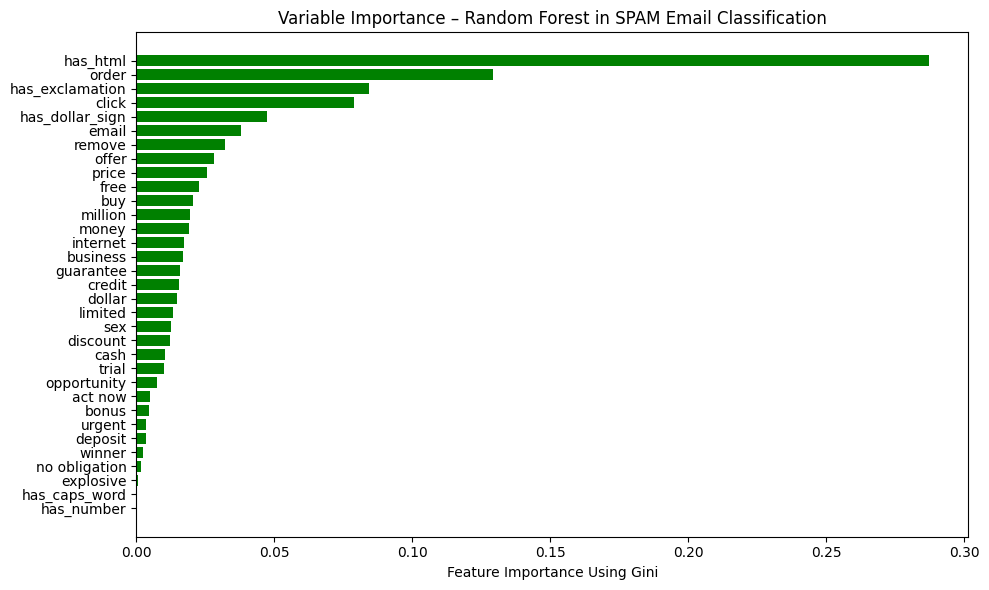

In [ ]:
#Feature Importance:

importances   = best_rf.feature_importances_
feature_names = X.columns.tolist()

top_idx      = np.argsort(importances)[::-1]
top_features = [feature_names[i] for i in top_idx]
top_imp      = importances[top_idx]

plt.figure(figsize=(10, 6))
plt.barh(top_features[::-1], top_imp[::-1], color="green")
plt.xlabel("Feature Importance Using Gini")
plt.title("Variable Importance – Random Forest in SPAM Email Classification")
plt.tight_layout()
plt.show()

It seems that the Naive Bayes Model from the previous homework was outperformed by the Ensemble Methods. According to the chart above, the most important variable was the existence of a clickable link or an HTML link in general. A lot of it also had to do with the word "order", which makes sense because a lot of spam emails have fake "orders" where they try to get you to click a link and steal your data.